# Chapter 13 · Monte Carlo Greeks: interactive demos

Companion to Chapter 13 of the [MFE 230D lecture notes](https://gennaroalberto.github.io/mfe230d-derivatives/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/mfe230d-derivatives/blob/main/code/notebooks/13-mc-greeks.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

Throughout, the test case is $S=K=100$, $T=1$, $r=1\%$, $y=2\%$, $\sigma=20\%$ (call price 7.36429), and
$S_T=S\exp(\nu T+\sigma\sqrt T Z)$ with $\nu=r-y-\sigma^2/2$. A Greek is estimated by **bumping** (finite
differences, with or without common random numbers), by the **pathwise** method (differentiate the payoff along
each draw), by the **likelihood ratio** method (differentiate the density), or by mixing the last two.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/mfe230d-derivatives#subdirectory=code"

import time
import warnings
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

from mfe230d import bs
from mfe230d import greeks as gr
from mfe230d.style import COBALT, GOLD, GREY, INK, use_style

warnings.simplefilter("ignore")
use_style()
GREEN, PURPLE = "#1BAF7A", "#6250D6"
P = bs.TEST_CASE
S, K, T, r, y, SIG = (P[k] for k in ("S", "K", "T", "r", "y", "sigma"))

## 1. How big a bump?

Proposition 13.1: the bias of a finite difference shrinks with the bump $h$, while its variance grows like
$1/(nh^2)$ with independent draws, stays bounded with common random numbers (CRN) for a Lipschitz payoff
(call delta, call vega), and grows like $1/(nh)$ with CRN when the payoff jumps (digital delta) or kinks (call gamma,
which needs a second difference). The curves are **exact**: the bias from the closed form, the variance by
quadrature. Dots mark the best bump of each scheme.

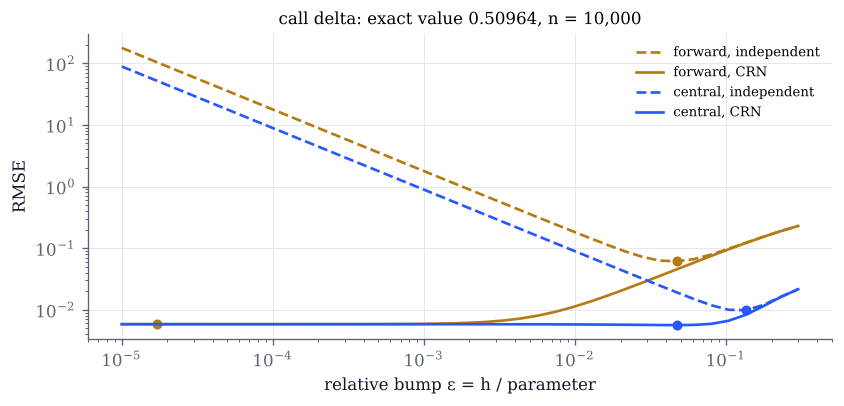

In [2]:
CASES = {"call delta": ("call", "S", ("forward", "central")),
         "call vega": ("call", "sigma", ("forward", "central")),
         "digital delta": ("digital", "S", ("forward", "central")),
         "call gamma": ("call", "S", ("second",))}

def bump_error(case="call delta", log10_n=4.0):
    kind, param, schemes = CASES[case]
    n = 10 ** log10_n
    base = P[param]
    eps = np.logspace(-5, np.log10(0.3), 40)
    fig, ax = plt.subplots(figsize=(8, 3.3))
    for scheme in schemes:
        for crn, ls in ((False, "--"), (True, "-")):
            col = GOLD if scheme == "forward" else COBALT
            rm = np.array([gr.fd_rmse(kind, param, e * base, n, scheme, crn, **P) for e in eps])
            ax.plot(eps, rm, color=col, ls=ls, label=f"{scheme}, {'CRN' if crn else 'independent'}")
            i = np.argmin(rm)
            ax.plot(eps[i], rm[i], "o", color=col, ms=5)
    ex = abs(float(gr.exact_greek(kind, "gamma" if case == "call gamma" else
                                  {"S": "delta", "sigma": "vega"}[param], **P)))
    ax.set(xscale="log", yscale="log", xlabel="relative bump ε = h / parameter", ylabel="RMSE",
           title=f"{case}: exact value {ex:.5g}, n = {n:,.0f}")
    ax.legend(fontsize=8); plt.show()

bump_error()

In [3]:
# Explore: which payoffs keep a flat error with CRN as the bump shrinks? How does the best bump move with n?
interact(bump_error,
         case=Dropdown(options=list(CASES), value="call delta", description="Greek"),
         log10_n=FloatSlider(value=4.0, min=2.0, max=8.0, step=0.5, continuous_update=False, description="log10 n"));

## 2. The course's shoot-out against the spot

As in Figure 13.2, one set of $n$ draws is reused for every $S_0$. Left: the central bumped delta, the pathwise delta
(with its $1/n$ steps) and the likelihood-ratio delta. Right: the bumped gamma, a kernel estimator with a tent of
width $2\varepsilon S$ per draw (Remark 13.3), against the PW-LR and LR-LR gammas of Proposition 13.8. With small
bumps and few draws, the bumped gamma is zero except where a draw's critical spot $K/G$ falls within $\varepsilon S$
of $S_0$.

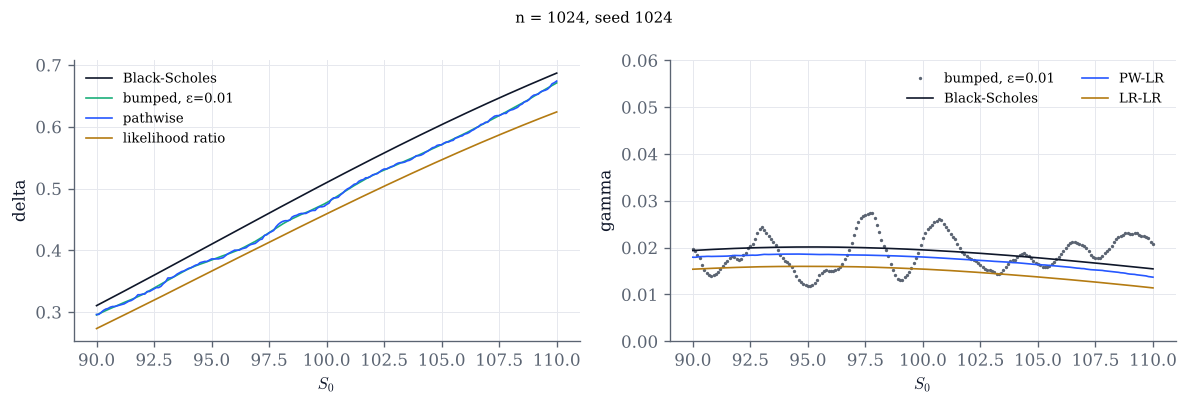

In [4]:
def shootout(n=1024, eps=0.01, seed=1024):
    z = np.random.default_rng(seed).standard_normal(n)
    Ss = np.linspace(90, 110, 201)
    rows = []
    for s in Ss:
        p = dict(P, S=s)
        fd = gr.fd_spot_greeks(z, "call", eps=eps, **p)
        g = gr.gamma_samples(z, "call", **p)
        rows.append((fd["delta_c"].mean(), gr.pathwise_samples(z, "call", **p)["delta"].mean(),
                     gr.lr_samples(z, "call", **p)["delta"].mean(), fd["gamma_c"].mean(),
                     g["pw_lr"].mean(), g["lr_lr"].mean()))
    q = np.array(rows)
    G = bs.greeks(Ss, K, T, r, y, SIG)
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.4))
    ax.plot(Ss, G["delta"], color=INK, lw=1, label="Black-Scholes")
    ax.plot(Ss, q[:, 0], color=GREEN, lw=1, label=f"bumped, ε={eps:g}")
    ax.plot(Ss, q[:, 1], color=COBALT, lw=1, label="pathwise")
    ax.plot(Ss, q[:, 2], color=GOLD, lw=1, label="likelihood ratio")
    ax.set(xlabel="$S_0$", ylabel="delta"); ax.legend(fontsize=8)
    bx.plot(Ss, q[:, 3], ".", ms=2, color=GREY, label=f"bumped, ε={eps:g}")
    bx.plot(Ss, G["gamma"], color=INK, lw=1, label="Black-Scholes")
    bx.plot(Ss, q[:, 4], color=COBALT, lw=1, label="PW-LR")
    bx.plot(Ss, q[:, 5], color=GOLD, lw=1, label="LR-LR")
    bx.set(xlabel="$S_0$", ylabel="gamma", ylim=(0, 0.06)); bx.legend(fontsize=8, ncol=2)
    fig.suptitle(f"n = {n}, seed {seed}", fontsize=9); fig.tight_layout(); plt.show()

shootout()

In [5]:
# Explore: increase n and watch the steps and the butterflies disappear; shrink ε at fixed n.
interact(shootout,
         n=IntSlider(value=1024, min=256, max=65536, step=256, continuous_update=False, description="n"),
         eps=Dropdown(options=[0.1, 0.03, 0.01, 0.003, 0.001], value=0.01, description="ε"),
         seed=IntSlider(value=1024, min=0, max=5000, continuous_update=False, description="seed"));

## 3. Variance per draw, and what happens as $\sigma\sqrt T\to0$

Exact per-draw standard deviations (quadrature) of the pathwise and likelihood-ratio estimators of each Greek of a
call, and of the three gamma estimators, as in Table 13.1. The likelihood-ratio weights grow like
$1/(\sigma\sqrt T)$ (Remark 13.7): with the strike below the forward (in the money), lower $\sigma$ or $T$ and
watch the likelihood-ratio deviations take off, while the pathwise ones stay bounded. Out of the money the payoff
vanishes on most draws and the likelihood-ratio variance falls with it.

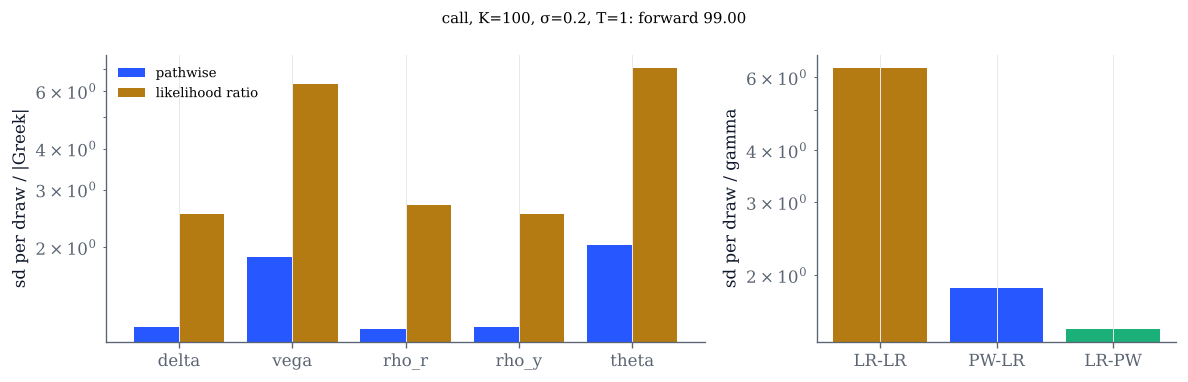

In [6]:
def variance_bars(K_=100.0, sigma=0.20, T_=1.0):
    p = dict(P, K=K_, sigma=sigma, T=T_)
    names = ["delta", "vega", "rho_r", "rho_y", "theta"]
    sd = lambda fn, g: np.sqrt(gr.estimator_moments(fn, g, "call", **p)[1])
    pw = [sd(gr.pathwise_samples, g) for g in names]
    lr = [sd(gr.lr_samples, g) for g in names]
    gm = [sd(gr.gamma_samples, g) for g in ("lr_lr", "pw_lr", "lr_pw")]
    ex = bs.greeks(**p)
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.2), gridspec_kw=dict(width_ratios=[5, 3]))
    x = np.arange(len(names))
    ax.bar(x - 0.2, np.array(pw) / np.abs([ex[g] for g in names]), 0.4, color=COBALT, label="pathwise")
    ax.bar(x + 0.2, np.array(lr) / np.abs([ex[g] for g in names]), 0.4, color=GOLD, label="likelihood ratio")
    ax.set_xticks(x, names); ax.set(yscale="log", ylabel="sd per draw / |Greek|"); ax.legend(fontsize=8)
    bx.bar(["LR-LR", "PW-LR", "LR-PW"], np.array(gm) / ex["gamma"], color=[GOLD, COBALT, GREEN])
    bx.set(yscale="log", ylabel="sd per draw / gamma")
    fig.suptitle(f"call, K={K_:g}, σ={sigma:g}, T={T_:g}: forward {S*np.exp((r-y)*T_):.2f}", fontsize=9)
    fig.tight_layout(); plt.show()

variance_bars()

In [7]:
interact(variance_bars,
         K_=FloatSlider(value=100.0, min=60.0, max=140.0, step=5.0, continuous_update=False, description="K"),
         sigma=FloatSlider(value=0.20, min=0.02, max=0.6, step=0.02, continuous_update=False, description="σ"),
         T_=FloatSlider(value=1.0, min=0.02, max=3.0, step=0.02, continuous_update=False, description="T"));

## 4. Along a path: Asian deltas and vegas

For an arithmetic Asian call with $m$ equally spaced fixings, the pathwise delta and vega stay well behaved as $m$
grows, while the likelihood-ratio delta uses only the first step (weight $Z_1/(S\sigma\sqrt{t_1})$) and the
likelihood-ratio vega sums $m$ scores; both standard deviations grow like $\sqrt m$ (Figure 13.3(a)).

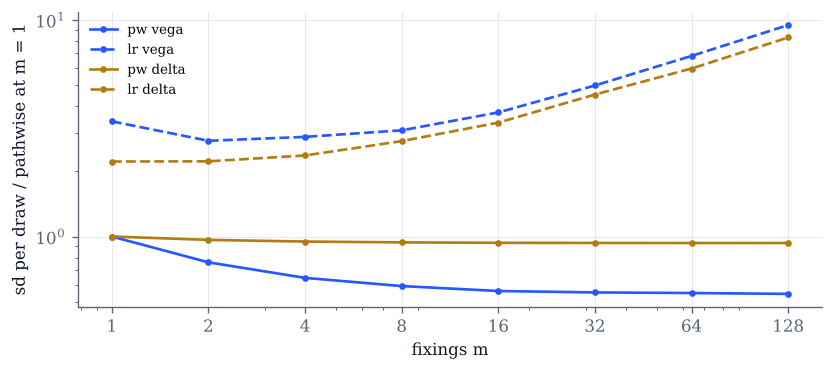

In [8]:
def asian_sd(log2_n=15, max_log2_m=7, seed=2026):
    rng = np.random.default_rng(seed)
    ms = 2 ** np.arange(0, max_log2_m + 1)
    out = {k: [] for k in ("pw_delta", "lr_delta", "pw_vega", "lr_vega")}
    for m in ms:
        s = gr.asian_samples(rng.standard_normal((2**log2_n, m)), **P)
        for k in out:
            out[k].append(s[k].std(ddof=1))
    fig, ax = plt.subplots(figsize=(8, 3.2))
    for k, col, ls in (("pw_vega", COBALT, "-"), ("lr_vega", COBALT, "--"), ("pw_delta", GOLD, "-"), ("lr_delta", GOLD, "--")):
        base = out["pw_vega"][0] if "vega" in k else out["pw_delta"][0]
        ax.plot(ms, np.array(out[k]) / base, "o" + ls, color=col, ms=3, label=k.replace("_", " "))
    ax.set(xscale="log", yscale="log", xlabel="fixings m", ylabel="sd per draw / pathwise at m = 1")
    ax.set_xticks(ms, [str(m) for m in ms]); ax.legend(fontsize=8); plt.show()

asian_sd()

In [9]:
interact(asian_sd,
         log2_n=IntSlider(value=15, min=12, max=17, continuous_update=False, description="log2 n"),
         max_log2_m=IntSlider(value=7, min=3, max=8, continuous_update=False, description="log2 max m"),
         seed=IntSlider(value=2026, min=0, max=5000, continuous_update=False, description="seed"));

## 5. Adjoints: all the bucketed vegas in one backward sweep

With a volatility $\sigma_j$ on each period, one forward and one backward sweep (Remark 13.9) give the price's
derivative with respect to $S$, $r$, $y$ and every $\sigma_j$. Central bumps need two repricings per input. The bars
are the adjoint, the dots the bumps with common random numbers; the title reports both running times on your
machine. Tilt the volatility term structure with the slider.

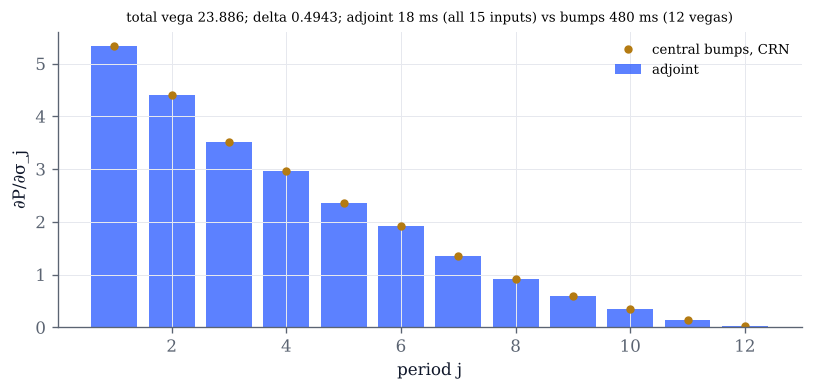

In [10]:
def buckets(m=12, tilt=0.0, log2_n=15, seed=2027):
    Z = np.random.default_rng(seed).standard_normal((2**log2_n, m))
    sig = SIG * (1 + tilt * (np.arange(1, m + 1) / m - 0.5))
    t0 = time.perf_counter()
    a = gr.asian_adjoint(Z, S, K, T, r, y, sig)
    t_adj = time.perf_counter() - t0
    h, bumped = 1e-4, []
    t0 = time.perf_counter()
    for j in range(m):
        e = np.zeros(m); e[j] = h
        up = gr.asian_adjoint(Z, S, K, T, r, y, sig + e)["price"]
        dn = gr.asian_adjoint(Z, S, K, T, r, y, sig - e)["price"]
        bumped.append(((up - dn) / (2 * h)).mean())
    t_bump = time.perf_counter() - t0
    v = a["vega"].mean(axis=0)
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.bar(np.arange(1, m + 1), v, color=COBALT, alpha=0.75, label="adjoint")
    ax.plot(np.arange(1, m + 1), bumped, "o", color=GOLD, ms=4, label="central bumps, CRN")
    ax.set(xlabel="period j", ylabel="∂P/∂σ_j",
           title=f"total vega {v.sum():.3f}; delta {a['delta'].mean():.4f}; "
                 f"adjoint {t_adj*1e3:.0f} ms (all {m + 3} inputs) vs bumps {t_bump*1e3:.0f} ms ({m} vegas)")
    ax.title.set_fontsize(8); ax.legend(fontsize=8); plt.show()

buckets()

In [11]:
interact(buckets,
         m=IntSlider(value=12, min=2, max=52, continuous_update=False, description="periods m"),
         tilt=FloatSlider(value=0.0, min=-1.0, max=1.0, step=0.1, continuous_update=False, description="vol tilt"),
         log2_n=IntSlider(value=15, min=12, max=17, continuous_update=False, description="log2 n"),
         seed=IntSlider(value=2027, min=0, max=5000, continuous_update=False, description="seed"));

## Things to try

- In section 1, pick the digital delta and move $n$ from $10^2$ to $10^8$: how fast does the best bump shrink with
  common random numbers, and with independent draws? Compare with the table after Proposition 13.1.
- In section 1, pick the call vega: why is the CRN error flat for every small bump, as for the call delta?
- In section 2, set $\varepsilon=0.001$ and raise $n$ until the bumped gamma stops looking like butterflies. How many
  draws fall in each tent on average?
- In section 3, take $K=80$ and lower $\sigma$ to $0.02$: which estimators blow up, and which stay bounded? Then set
  $K$ to the forward and repeat.
- In section 5, raise $m$ to 52 (weekly periods): how do the two running times scale with $m$?